<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [NOAA Tides](https://github.com/Query-farm/vgi-tides)

NOAA CO-OPS tide and current stations, predictions and observations for marine analysis.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-tides/blob/main/notebooks/02_same_station_different_current_measurements.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-tides/blob/main/notebooks/README.md)


## 02 · Same station and bin still leave a comparison gap

At **Cherry Point, station cp0101**, can observed current speed be subtracted from
predicted signed major-axis velocity? We inspect product units and station metadata,
choose an observation bin, and test station/bin/time alignment before computing any
residual. Matching an identifier cannot supply missing depth or align different clocks.

Default replay inputs are **unchanged official NOAA HTTP responses**, captured on 14 November
2026, with one UTC measurement day: **13 November 2026**. [Capture provenance](current_recordings/provenance.json)
retains original URLs, request parameters, times and hashes. No synthetic values,
nearest-time join, interpolation or zero-filled missing observations are used.
This historical analysis is not a navigation or current-warning product.

### Select an observation bin without changing the source population

`OBSERVATION_BIN = 1` selects the first recorded observation bin; choose **20** for
the experiment. Both observation bins and prediction bin 20 are always fetched once,
so only the local comparison selection changes. Prediction bin 20 was verified in
the recorded NOAA station metadata; an arbitrary default bin is not assumed valid.

`DATA_MODE = "replay"` is the reproducible default. Explicit `"live"` uses the same
bounded queries against NOAA; current metadata or historical observations may be
revised. The metadata capture is not proof of a historical deployment configuration.

In [1]:
OBSERVATION_BIN = 1  # Experiment: 20.
DATA_MODE = "replay"  # Explicit alternative: "live"; no fallback.

### Run this notebook

Read the saved results on GitHub or choose **Open in Colab** and Run All. Shared
base tools preserve compatible preloaded plotting/data libraries; local publication
uses the optional `[runner]` extra. Initial packages, verified companions, VGI and
the native worker release need internet. Default replay then uses unchanged public
NOAA responses served on loopback. Live is an explicit choice and never falls back.

No Bun runtime, worker checkout, local build or credential is required. A fresh
preloaded Python 3.12 notebook-only run verifies setup; hosted Colab itself is untested.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.36":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.36"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.36":
    raise RuntimeError("Install shared tools 0.3.36, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("tides")
from tides_source import TidesSource

%matplotlib inline
theme()
session = connect(globals())
connection = session.connection
Path("artifacts").mkdir(exist_ok=True)

if type(OBSERVATION_BIN) is not int or OBSERVATION_BIN not in {1, 20}:
    raise ValueError("OBSERVATION_BIN must be 1 or 20")
source = TidesSource(DATA_MODE, "currents")
PROVENANCE = (
    "Source: NOAA CO-OPS · replay public responses · captured 2026-11-14 · Cherry Point cp0101"
    if DATA_MODE == "replay"
    else f"Source: NOAA CO-OPS · live retrieval {source.run_utc[:19]} UTC · Cherry Point cp0101"
)

### Discover the product and station before comparing values

`products` distinguishes observed currents from current predictions even though both
are returned in **m/s**. The prediction is a **signed component along the major axis**;
observed speed is a nonnegative magnitude, with a separate direction. They are not
interchangeable scalar measurements. Neither is a water height in metres.

Materialize each metadata collection once before filtering locally. The released
`stations()` lacks the prediction-bin column added on current main. It still provides
station identity and coordinates. The local raw-metadata query below makes the
recorded bin choice visible; it does not pretend that column is available in v0.1.0.
Prediction station rows may repeat by bin, so never join the full collection to a
time series using station ID alone without resolving that multiplicity.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tides' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-tides@v0.1.0');

,Success


In [5]:
%%sql
CREATE TABLE product_units AS SELECT * FROM tides.main.products;
CREATE TABLE observation_stations AS SELECT * FROM tides.main.stations(station_kind:='currents');
CREATE TABLE prediction_stations AS SELECT * FROM tides.main.stations(station_kind:='currentpredictions');
CREATE TABLE observation_bins AS SELECT * FROM tides.main.current_bins('cp0101');
SELECT * FROM product_units WHERE sql_function IN ('currents','current_predictions','current_bins') ORDER BY sql_function;
SELECT station_id,name,latitude,longitude,station_kind FROM observation_stations WHERE station_id='cp0101';
SELECT station_id,name,latitude,longitude,station_kind,station_type FROM prediction_stations WHERE station_id='cp0101';
SELECT station_id,bin,depth_m,qc_flag FROM observation_bins WHERE bin IN (1,20) ORDER BY bin;
SELECT s.id AS station_id,s.currbin AS recorded_prediction_bin,s.type AS recorded_station_type
FROM (SELECT unnest(stations) AS s FROM read_json_auto('current_recordings/stations-currentpredictions.json'))
WHERE s.id='cp0101' ORDER BY s.currbin;

,station_id,recorded_prediction_bin,recorded_station_type
0,cp0101,20,H


### A bin number is an identifier, not a depth in metres

The current observation metadata lists 30 bins, but **every `depth_m` is NULL** in
this capture. We retain those missing depths. Other raw metadata includes distances,
but a distance is not automatically vertical depth and is not substituted for it.
The prediction supplies a depth for its bin; that does not establish the observation
sensor's depth or historical deployment. Quality-control codes are preserved without
inventing an operational certification.

Each explicit observation-bin request returns six-minute samples. The prediction
also uses interval 6. Equal spacing does not ensure equal timestamps: inspect the
actual UTC phase before joining. The source API dates are inclusive; the returned
window is [2026-11-13 00:00, 2026-11-14 00:00) UTC.

In [6]:
%%sql
CREATE TABLE observed_bin1 AS SELECT * FROM tides.main.currents('cp0101','2026-11-13','2026-11-13',bin:=1);
CREATE TABLE observed_bin20 AS SELECT * FROM tides.main.currents('cp0101','2026-11-13','2026-11-13',bin:=20);
CREATE TABLE observed AS SELECT * FROM observed_bin1 UNION ALL SELECT * FROM observed_bin20;
CREATE TABLE predicted AS SELECT * FROM tides.main.current_predictions(
 'cp0101','2026-11-13','2026-11-13',bin:=20,step:='6');
CREATE TABLE selected AS SELECT * FROM observed WHERE bin={{OBSERVATION_BIN}};
SELECT bin,count(*) AS samples,count(speed_mps) AS available_speeds,count(direction_deg) AS available_directions,
 count(flags) AS supplied_flags,min(time) AT TIME ZONE 'UTC' AS first_utc,
 max(time) AT TIME ZONE 'UTC' AS last_utc FROM observed GROUP BY bin ORDER BY bin;
SELECT bin,count(*) AS samples,min(depth_m) AS prediction_depth_m,min(velocity_major_mps) AS min_signed_mps,
 max(velocity_major_mps) AS max_signed_mps,min(flood_direction_deg) AS mean_flood_direction_deg,
 min(ebb_direction_deg) AS mean_ebb_direction_deg FROM predicted GROUP BY bin;

,bin,samples,prediction_depth_m,min_signed_mps,max_signed_mps,mean_flood_direction_deg,mean_ebb_direction_deg
0,20,240,14.3,-0.237,0.277,7.0,179.0


In [7]:
%%sql
CREATE TABLE comparison_gate AS
SELECT (SELECT count(*) FROM selected) AS selected_observations,
 (SELECT count(*) FROM selected WHERE station_id IN (SELECT station_id FROM predicted)) AS same_station,
 (SELECT count(*) FROM selected WHERE (station_id,bin) IN (SELECT station_id,bin FROM predicted)) AS same_station_bin,
 (SELECT count(*) FROM selected o JOIN predicted p USING(station_id,bin,time)) AS exact_pairs,
 (SELECT count(*) FROM selected o JOIN observation_bins b USING(station_id,bin) WHERE b.depth_m IS NOT NULL)
 AS with_observation_depth;
SELECT * FROM comparison_gate;
SELECT 'observed' AS source,mod(date_part('minute',time),6) AS minute_phase,count(*) AS samples
FROM selected GROUP BY ALL
UNION ALL
SELECT 'predicted',mod(date_part('minute',time),6),count(*) FROM predicted GROUP BY ALL;
SELECT o.time AT TIME ZONE 'UTC' AS observed_utc,o.bin,o.speed_mps,
 p.time AT TIME ZONE 'UTC' AS exact_prediction_utc,p.velocity_major_mps
FROM selected o LEFT JOIN predicted p USING(station_id,bin,time)
ORDER BY o.time LIMIT 5;

,observed_utc,bin,speed_mps,exact_prediction_utc,velocity_major_mps
0,2026-11-13 00:03:00,1,0.066,NaT,NaN
1,2026-11-13 00:09:00,1,0.044,NaT,NaN
2,2026-11-13 00:15:00,1,0.031,NaT,NaN
3,2026-11-13 00:21:00,1,0.070,NaT,NaN
4,2026-11-13 00:27:00,1,0.039,NaT,NaN


In [8]:
%%sql gate <<
SELECT * FROM comparison_gate;

In [9]:
g = gate.iloc[0]
prose(
    f"Observation bin **{OBSERVATION_BIN}** has **{int(g.selected_observations)} samples**. "
    f"All **{int(g.same_station)}** share the prediction station, **{int(g.same_station_bin)}** also share "
    f"its bin identifier, and **{int(g.exact_pairs)}** share the exact station/bin/time key. "
    f"Observation-depth metadata is present for **{int(g.with_observation_depth)} samples**. "
    "The exact left join therefore keeps missing predictions as NULL. No observed-minus-predicted "
    "current residual is computed: timestamps differ, observation depth is unknown, and scalar speed "
    "is not the predicted signed component. Mean flood/ebb bearings are not "
    "instantaneous observed directions."
)

Observation bin **1** has **240 samples**. All **240** share the prediction station, **0** also share its bin identifier, and **0** share the exact station/bin/time key. Observation-depth metadata is present for **0 samples**. The exact left join therefore keeps missing predictions as NULL. No observed-minus-predicted current residual is computed: timestamps differ, observation depth is unknown, and scalar speed is not the predicted signed component. Mean flood/ebb bearings are not instantaneous observed directions.

In [10]:
%%sql speed_series <<
SELECT time AT TIME ZONE 'UTC' AS time_utc,bin,speed_mps,direction_deg FROM observed ORDER BY bin,time;

In [11]:
%%sql prediction_series <<
SELECT time AT TIME ZONE 'UTC' AS time_utc,bin,velocity_major_mps,depth_m FROM predicted ORDER BY time;

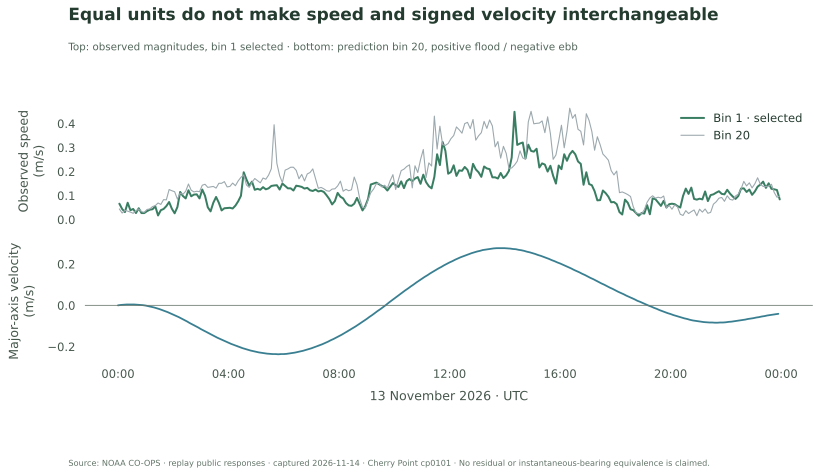

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7), sharex=True)
for bin_id, group in speed_series.groupby("bin"):
    focus = bin_id == OBSERVATION_BIN
    axes[0].plot(
        group.time_utc,
        group.speed_mps,
        color="#397D62" if focus else "#9BA8AD",
        linewidth=2 if focus else 1.1,
        label=f"Bin {bin_id}" + (" · selected" if focus else ""),
    )
axes[0].set_ylabel("Observed speed\n(m/s)")
axes[0].set_ylim(bottom=0)
axes[0].legend(loc="upper right")
axes[1].plot(prediction_series.time_utc, prediction_series.velocity_major_mps, color="#397F91", linewidth=1.8)
axes[1].axhline(0, color="#66756C", linewidth=0.8)
axes[1].set_ylabel("Major-axis velocity\n(m/s)")
axes[1].set_xlabel("13 November 2026 · UTC")
axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
finish(
    fig,
    "Equal units do not make speed and signed velocity interchangeable",
    f"Top: observed magnitudes, bin {OBSERVATION_BIN} selected · "
    "bottom: prediction bin 20, positive flood / negative ebb",
    PROVENANCE + " · No residual or instantaneous-bearing equivalence is claimed.",
    name=f"speed-and-velocity-{OBSERVATION_BIN}",
)

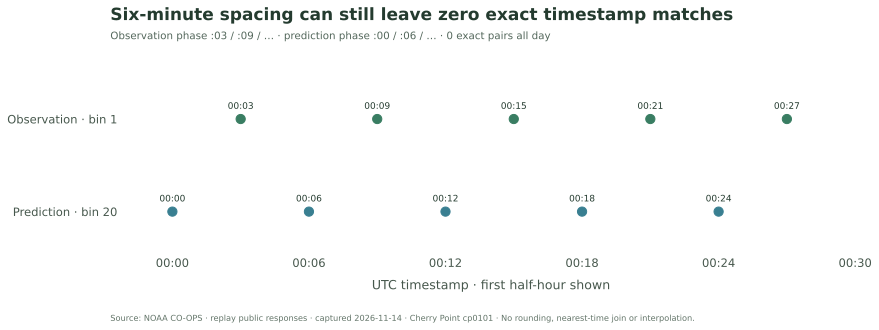

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 4.8))
obs = speed_series[
    (speed_series.bin == OBSERVATION_BIN) & (speed_series.time_utc < pd.Timestamp("2026-11-13 00:30"))
]
pred = prediction_series[prediction_series.time_utc < pd.Timestamp("2026-11-13 00:30")]
ax.scatter(obs.time_utc, np.ones(len(obs)), color="#397D62", s=85)
ax.scatter(pred.time_utc, np.zeros(len(pred)), color="#397F91", s=85)
for values, y in [(obs.time_utc, 1), (pred.time_utc, 0)]:
    for value in values:
        ax.text(value, y + 0.11, value.strftime("%H:%M"), ha="center", fontsize=9)
ax.set_yticks([0, 1], ["Prediction · bin 20", f"Observation · bin {OBSERVATION_BIN}"])
ax.set_ylim(-0.4, 1.5)
ax.set_xlim(pd.Timestamp("2026-11-12 23:58"), pd.Timestamp("2026-11-13 00:30"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 6, 12, 18, 24, 30]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("UTC timestamp · first half-hour shown")
finish(
    fig,
    "Six-minute spacing can still leave zero exact timestamp matches",
    "Observation phase :03 / :09 / … · prediction phase :00 / :06 / … · "
    f"{int(g.exact_pairs)} exact pairs all day",
    PROVENANCE + " · No rounding, nearest-time join or interpolation.",
    name=f"timestamp-phase-{OBSERVATION_BIN}",
)

### Verify units, population and the comparison boundary

Check each source's keys and UTC extent before interpreting the gate. Raw recorded
JSON supplies an independent unit check: the worker converts cm/s to m/s exactly by
100, and predicted signs are retained. Current flags are absent here; NULL is not a
clean-quality certificate. A nonmatching prediction remains NULL, never zero.

The reference units describe a product, not a physical comparability guarantee.
Replay expects exactly six requests: two station collections, bin metadata, two
observation-bin series and one prediction series. Both bins are fetched regardless
of the selected comparison, so the experiment leaves every returned source row fixed.

In [14]:
%%sql
CREATE TABLE raw_observed AS
SELECT unnest(data) AS r FROM read_json_auto('current_recordings/currents-cp0101-bin1.json')
UNION ALL SELECT unnest(data) AS r FROM read_json_auto('current_recordings/currents-cp0101-bin20.json');
CREATE TABLE raw_predicted AS
SELECT unnest(current_predictions.cp) AS r FROM read_json_auto('current_recordings/predictions-cp0101-bin20.json');
SELECT max(abs(o.speed_mps-r.r.s::DOUBLE/100)) AS max_speed_conversion_error_mps
FROM observed o JOIN raw_observed r ON o.time=CAST(r.r.t||'+00' AS TIMESTAMPTZ) AND o.bin=r.r.b::INTEGER;
SELECT max(abs(p.velocity_major_mps-r.r.Velocity_Major::DOUBLE/100)) AS max_velocity_conversion_error_mps
FROM predicted p JOIN raw_predicted r ON p.time=CAST(r.r.Time||'+00' AS TIMESTAMPTZ) AND p.bin=r.r.Bin::INTEGER;

,max_velocity_conversion_error_mps
0,0.0


In [15]:
%%sql checks <<
SELECT '480 unique observation keys' AS check_name,count(*)=480 AND count(DISTINCT(station_id,bin,time))=480 AS passed FROM observed
UNION ALL SELECT '240 unique prediction keys',count(*)=240 AND count(DISTINCT(station_id,bin,time))=240 FROM predicted
UNION ALL SELECT '240 selected samples',count(*)=240 FROM selected
UNION ALL SELECT 'same station',bool_and(station_id='cp0101') FROM observed
UNION ALL SELECT 'observed speed present nonnegative',count(speed_mps)=480 AND min(speed_mps)>=0 FROM observed
UNION ALL SELECT 'observed directions bounded',count(direction_deg)=480 AND min(direction_deg)>=0 AND max(direction_deg)<=360 FROM observed
UNION ALL SELECT 'missing flags retained',count(flags)=0 FROM observed
UNION ALL SELECT 'missing observation depth retained',count(*)=30 AND count(depth_m)=0 FROM observation_bins
UNION ALL SELECT 'signed prediction preserves both directions',min(velocity_major_mps)<0 AND max(velocity_major_mps)>0 FROM predicted
UNION ALL SELECT 'exact pairs absent',exact_pairs=0 FROM comparison_gate
UNION ALL SELECT 'bin gate changes explicitly',same_station_bin=CASE WHEN {{OBSERVATION_BIN}}=20 THEN 240 ELSE 0 END FROM comparison_gate
UNION ALL SELECT 'observed grid phase three',bool_and(mod(date_part('minute',time),6)=3) FROM observed
UNION ALL SELECT 'predicted grid phase zero',bool_and(mod(date_part('minute',time),6)=0) FROM predicted
UNION ALL SELECT 'observation conversion matches recording',count(*)=480 AND max(abs(o.speed_mps-r.r.s::DOUBLE/100))<1e-12 FROM observed o JOIN raw_observed r ON o.time=CAST(r.r.t||'+00' AS TIMESTAMPTZ) AND o.bin=r.r.b::INTEGER
UNION ALL SELECT 'prediction conversion matches recording',count(*)=240 AND max(abs(p.velocity_major_mps-r.r.Velocity_Major::DOUBLE/100))<1e-12 FROM predicted p JOIN raw_predicted r ON p.time=CAST(r.r.Time||'+00' AS TIMESTAMPTZ) AND p.bin=r.r.Bin::INTEGER
UNION ALL SELECT 'source timestamps inside requested UTC day',bool_and(time>=TIMESTAMPTZ '2026-11-13 00:00:00+00' AND time<TIMESTAMPTZ '2026-11-14 00:00:00+00') FROM (SELECT time FROM observed UNION ALL SELECT time FROM predicted);

In [16]:
display(checks)
assert len(checks) == 16 and checks.passed.all()
prose(f"**All {len(checks)} SQL checks pass.** " + source.audit())
Path("artifacts/currents-audit.json").write_text(
    json.dumps(
        {
            "data_mode": DATA_MODE,
            "observation_bin": OBSERVATION_BIN,
            "gate": gate.to_dict("records"),
            "speed_series": speed_series.to_dict("records"),
            "prediction_series": prediction_series.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,480 unique observation keys,True
1,240 unique prediction keys,True
2,240 selected samples,True
3,same station,True
4,observed speed present nonnegative,True
5,observed directions bounded,True
6,missing flags retained,True
7,missing observation depth retained,True
8,signed prediction preserves both directions,True
9,exact pairs absent,True


**All 16 SQL checks pass.** Replay audit: exactly 6 bounded requests with unchanged NOAA response bytes.

95461

### One change to test

Change only **OBSERVATION_BIN from 1 to 20** in replay mode. The station-and-bin gate
should admit all 240 selected observations, but the exact-time gate should still
admit zero. The selected observed curve changes while both complete observation
series and the signed prediction remain identical. Observation depth remains NULL.

Choosing a matching bin solves only one identity condition. A later analysis would
need an explicit temporal model and compatible measurement/axis/deployment context;
this notebook does not invent them. It makes the unresolved boundaries inspectable.
Restore bin 1 afterward. [Setup, data provenance and live limits](README.md).

In [17]:
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-tides](https://github.com/Query-farm/vgi-tides)